# Geração Horária e Carga — ONS

Parte do projeto **O Impacto dos Data Centers na Demanda Elétrica Brasileira até 2036: Uma Análise com Dados do ONS, ANEEL e EPE**. Os gráficos e correlações utilizam setembro e outubro de 2026; novembro parcial é usado apenas para diagnóstico. A carga é uma série histórica publicada pelo ONS com componentes estimados.


In [1]:

from pathlib import Path
import pandas as pd
import pyarrow.parquet as pq

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

arquivos = sorted(
    (BASE_DIR / "data/raw/ons/geracao")
    .rglob("*.parquet")
)

print("Arquivos encontrados:", len(arquivos))

if not arquivos:
    raise FileNotFoundError(
        "Nenhum Parquet encontrado."
    )

# Inspecionar apenas o arquivo mais recente.
arquivo = arquivos[-1]

parquet = pq.ParquetFile(arquivo)

print("\nArquivo:", arquivo.name)
print("Registros:", parquet.metadata.num_rows)
print("\nSchema:")
print(parquet.schema_arrow)

# O esquema e os totais são suficientes para esta inspeção.


Arquivos encontrados: 3

Arquivo: geracao_usina_2026_11.parquet
Registros: 132672

Schema:
din_instante: timestamp[ns]
id_subsistema: string
nom_subsistema: string
id_estado: string
nom_estado: string
cod_modalidadeoperacao: string
nom_tipousina: string
nom_tipocombustivel: string
nom_usina: string
id_ons: string
ceg: string
val_geracao: double
-- schema metadata --
pandas: '{"index_columns": [], "column_indexes": [], "columns": [{"name":' + 1566


## 2. Validação Temporal
Verificação dos intervalos horários e da cobertura dos dados.

In [2]:

import pandas as pd

# Novembro de 2026, já identificado na etapa anterior
arquivo = arquivos[-1]

df = pd.read_parquet(arquivo)

df["din_instante"] = pd.to_datetime(
    df["din_instante"]
)

print("Registros:", len(df))
print("Primeira data:", df["din_instante"].min())
print("Última data:", df["din_instante"].max())

print("\nQuantidade de horários distintos:")
print(df["din_instante"].nunique())

print("\nRegistros por dia:")
display(
    df.groupby(df["din_instante"].dt.date)
      .size()
      .rename("registros")
      .to_frame()
)

print("\nHoras disponíveis:")
print(sorted(df["din_instante"].dt.hour.unique()))


Registros: 132672
Primeira data: 2026-11-01 00:00:00
Última data: 2026-11-08 23:00:00

Quantidade de horários distintos:
192

Registros por dia:


,registros
din_instante,
2026-11-01,16584
2026-11-02,16584
2026-11-03,16584
2026-11-04,16584
2026-11-05,16584
2026-11-06,16584
2026-11-07,16584
2026-11-08,16584



Horas disponíveis:
[np.int32(0), np.int32(1), np.int32(2), np.int32(3), np.int32(4), np.int32(5), np.int32(6), np.int32(7), np.int32(8), np.int32(9), np.int32(10), np.int32(11), np.int32(12), np.int32(13), np.int32(14), np.int32(15), np.int32(16), np.int32(17), np.int32(18), np.int32(19), np.int32(20), np.int32(21), np.int32(22), np.int32(23)]


## 3. Modalidades e Fontes de Geração

O recorte analítico seleciona **TIPO I** e **Conjunto de Usinas**, abrangendo hidrelétrica, térmica, eólica e solar. O ONS informa que conjuntos reúnem usinas Tipo II-C e que grupos de pequenas usinas Tipo III usam previsões; manter conjuntos sem somá-los às modalidades individuais ajuda a evitar sobreposição, sem provar ausência de dupla contagem. II-A, II-B, II-C individuais, Tipo III e MMGD não entram neste recorte; a fonte nuclear também não integra os quatro grupos analisados. A seleção não é a geração nacional completa nem um balanço energético.

A cobertura mede preenchimento dos registros recebidos e não demonstra completude do universo de usinas. Há 1.464 registros térmicos ausentes em setembro–outubro no recorte; as somas térmicas são valores disponíveis, potencialmente incompletos. Nulos e negativos são preservados e sinalizados, sem atribuir uma causa aos negativos. [Catálogo e dicionário ONS](https://dados.ons.org.br/dataset/geracao-usina-2).


In [3]:

print("MODALIDADES OPERACIONAIS")
display(
    df["cod_modalidadeoperacao"]
    .value_counts(dropna=False)
    .rename_axis("modalidade")
    .reset_index(name="registros")
)

print("\nTIPOS DE USINA")
display(
    df["nom_tipousina"]
    .value_counts(dropna=False)
    .rename_axis("tipo")
    .reset_index(name="registros")
)

print("\nMODALIDADES POR TIPO")
display(
    pd.crosstab(
        df["cod_modalidadeoperacao"].fillna("NULO"),
        df["nom_tipousina"]
    )
)


MODALIDADES OPERACIONAIS


,modalidade,registros
0,TIPO I,47616
1,Conjunto de Usinas,47424
2,Pequenas Usinas (Tipo III),15168
3,TIPO II-B,8256
4,Pequenas Usinas (MMGD),7296
5,TIPO II-A,3648
6,TIPO III,3264



TIPOS DE USINA


,tipo,registros
0,HIDROELÉTRICA,39552
1,TÉRMICA,33984
2,EOLIELÉTRICA,32064
3,FOTOVOLTAICA,26688
4,NUCLEAR,384



MODALIDADES POR TIPO


nom_tipousina,EOLIELÉTRICA,FOTOVOLTAICA,HIDROELÉTRICA,NUCLEAR,TÉRMICA
cod_modalidadeoperacao,,,,,
Conjunto de Usinas,27072,16128,960,0,3264
Pequenas Usinas (MMGD),0,7296,0,0,0
Pequenas Usinas (Tipo III),2688,2112,5952,0,4416
TIPO I,1344,0,29376,384,16512
TIPO II-A,0,0,1344,0,2304
TIPO II-B,960,1152,384,0,5760
TIPO III,0,0,1536,0,1728


## 4. Qualidade e Granularidade
Verificação de valores ausentes, negativos e registros potencialmente duplicados.

In [4]:

print("VALORES AUSENTES")
display(df.isna().sum())

print("\nESTATÍSTICAS DE GERAÇÃO")
display(df["val_geracao"].describe())

print("\nValores negativos:",
      df["val_geracao"].lt(0).sum())

print("Valores zerados:",
      df["val_geracao"].eq(0).sum())

print("Linhas idênticas:",
      df.duplicated().sum())

# Identificação provisória:
# horário + subsistema + estado + modalidade + usina
chave = [
    "din_instante",
    "id_subsistema",
    "id_estado",
    "cod_modalidadeoperacao",
    "nom_tipousina",
    "nom_usina",
]

duplicados = df.duplicated(
    subset=chave,
    keep=False
)

print("\nRegistros com chave provisória repetida:",
      duplicados.sum())

# O total de duplicados permanece visível sem exibir registros individuais.


VALORES AUSENTES


din_instante                  0
id_subsistema                 0
nom_subsistema                0
id_estado                     0
nom_estado                    0
cod_modalidadeoperacao        0
nom_tipousina                 0
nom_tipocombustivel           0
nom_usina                     0
id_ons                    22464
ceg                           0
val_geracao                7488
dtype: int64


ESTATÍSTICAS DE GERAÇÃO


count    125184.000000
mean        131.714786
std         351.257869
min           0.000000
25%           0.019000
50%          28.761609
75%         103.609878
max        6213.815263
Name: val_geracao, dtype: float64


Valores negativos: 0
Valores zerados: 30830


Linhas idênticas: 0



Registros com chave provisória repetida: 0


## 5. Diagnóstico dos Valores Ausentes
Distribuição dos registros sem informação de geração por modalidade e fonte.

In [5]:

# Diagnóstico dos valores ausentes
df_nulos = (
    df.assign(
        geracao_ausente=df["val_geracao"].isna()
    )
    .groupby(
        ["cod_modalidadeoperacao", "nom_tipousina"],
        as_index=False
    )
    .agg(
        registros=("val_geracao", "size"),
        nulos=("geracao_ausente", "sum")
    )
)

df_nulos["percentual_nulos"] = (
    df_nulos["nulos"] /
    df_nulos["registros"] * 100
)

df_nulos = df_nulos.sort_values(
    "nulos",
    ascending=False
)

display(
    df_nulos[df_nulos["nulos"] > 0]
)


,cod_modalidadeoperacao,nom_tipousina,registros,nulos,percentual_nulos
18,TIPO II-B,TÉRMICA,5760,4032,70.000000
20,TIPO III,TÉRMICA,1728,1728,100.000000
19,TIPO III,HIDROELÉTRICA,1536,1344,87.500000
3,Conjunto de Usinas,TÉRMICA,3264,192,5.882353
17,TIPO II-B,HIDROELÉTRICA,384,192,50.000000


In [6]:

# Verificar quantidade de nulos por horário
nulos_horarios = (
    df.groupby("din_instante")["val_geracao"]
    .apply(lambda x: x.isna().sum())
)

print("Nulos por horário:")
display(nulos_horarios.describe())

# Identificar os empreendimentos com mais nulos
resumo_usinas = (
    df[df["val_geracao"].isna()]
    .groupby(
        ["cod_modalidadeoperacao",
         "nom_tipousina",
         "nom_usina"],
        as_index=False
    )
    .size()
    .rename(columns={"size": "registros_nulos"})
    .sort_values("registros_nulos", ascending=False)
)

display(
    resumo_usinas.groupby(["cod_modalidadeoperacao", "nom_tipousina"], as_index=False)
    .agg(entidades=("nom_usina", "size"), registros_nulos=("registros_nulos", "sum"))
)


Nulos por horário:

count    192.0
mean      39.0
std        0.0
min       39.0
25%       39.0
50%       39.0
75%       39.0
max       39.0
Name: val_geracao, dtype: float64

,cod_modalidadeoperacao,nom_tipousina,entidades,registros_nulos
0,Conjunto de Usinas,TÉRMICA,1,192
1,TIPO II-B,HIDROELÉTRICA,1,192
2,TIPO II-B,TÉRMICA,21,4032
3,TIPO III,HIDROELÉTRICA,7,1344
4,TIPO III,TÉRMICA,9,1728


## 6. Validação das Camadas Silver e Gold
Verificação das agregações horárias e da cobertura dos dados.

In [7]:

from pathlib import Path
import pandas as pd

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

PASTA_GOLD = (
    BASE_DIR / "data/gold/ons/geracao"
)

df_horaria = pd.read_parquet(
    PASTA_GOLD / "geracao_horaria.parquet"
)

df_qualidade = pd.read_parquet(
    PASTA_GOLD / "qualidade_geracao.parquet"
)

print("Dimensões Gold horária:", df_horaria.shape)
print("Dimensões Gold qualidade:", df_qualidade.shape)

print("\nAmostra da Gold:")
display(df_horaria.head(10))

print("\nQualidade por modalidade:")
display(
    df_qualidade.groupby(
        "cod_modalidadeoperacao",
        as_index=False
    ).agg(
        registros=("registros", "sum"),
        nulos=("nulos", "sum")
    )
)


Dimensões Gold horária: (92568, 15)
Dimensões Gold qualidade: (67, 11)

Amostra da Gold:


,din_instante,id_subsistema,nom_tipousina,cod_modalidadeoperacao,grupo_modalidade,registros,registros_validos,valores_ausentes,valores_negativos,valores_zero,geracao_soma,cobertura_pct,ano,mes,hora
0,2026-09-01,N,EOLIELÉTRICA,Conjunto de Usinas,Conjuntos de usinas,1,1,0,0,0,371.755000,100.0,2026,9,0
1,2026-09-01,N,FOTOVOLTAICA,Pequenas Usinas (MMGD),MMGD,8,8,0,0,8,0.000000,100.0,2026,9,0
2,2026-09-01,N,FOTOVOLTAICA,Pequenas Usinas (Tipo III),Pequenas usinas Tipo III,1,1,0,0,1,0.000000,100.0,2026,9,0
3,2026-09-01,N,HIDROELÉTRICA,Pequenas Usinas (Tipo III),Pequenas usinas Tipo III,1,1,0,0,0,43.000000,100.0,2026,9,0
4,2026-09-01,N,HIDROELÉTRICA,TIPO I,Demais modalidades,10,10,0,0,0,3353.692763,100.0,2026,9,0
5,2026-09-01,N,TÉRMICA,Pequenas Usinas (Tipo III),Pequenas usinas Tipo III,3,3,0,0,1,38.500000,100.0,2026,9,0
6,2026-09-01,N,TÉRMICA,TIPO I,Demais modalidades,28,28,0,0,8,2887.231000,100.0,2026,9,0
7,2026-09-01,N,TÉRMICA,TIPO II-B,Demais modalidades,1,1,0,0,0,198.000000,100.0,2026,9,0
8,2026-09-01,NE,EOLIELÉTRICA,Conjunto de Usinas,Conjuntos de usinas,130,130,0,0,1,17974.565000,100.0,2026,9,0
9,2026-09-01,NE,EOLIELÉTRICA,Pequenas Usinas (Tipo III),Pequenas usinas Tipo III,9,9,0,0,0,550.275000,100.0,2026,9,0



Qualidade por modalidade:


,cod_modalidadeoperacao,registros,nulos
0,Conjunto de Usinas,379512,1656
1,Pequenas Usinas (MMGD),62928,0
2,Pequenas Usinas (Tipo III),130824,0
3,TIPO I,410688,0
4,TIPO II-A,31464,0
5,TIPO II-B,64128,29352
6,TIPO II-C,82200,72216
7,TIPO III,28152,26496


## 7. Diagnóstico de Valores Negativos
Investigação dos registros de geração negativa por fonte e modalidade.

In [8]:

from pathlib import Path
import pandas as pd

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

arquivo = (
    BASE_DIR / "data/raw/ons/geracao/2026/"
    "geracao_usina_2026_09.parquet"
)

df_setembro = pd.read_parquet(arquivo)

negativos = df_setembro[
    df_setembro["val_geracao"] < 0
].copy()

print("Total de registros:", len(df_setembro))
print("Registros negativos:", len(negativos))

if not negativos.empty:
    print("\nMenor valor:", negativos["val_geracao"].min())
    print("Maior valor negativo:", negativos["val_geracao"].max())

    print("\nNegativos por modalidade e fonte:")
    display(
        negativos.groupby(
            ["cod_modalidadeoperacao", "nom_tipousina"],
            dropna=False
        ).agg(
            registros=("val_geracao", "size"),
            menor_valor=("val_geracao", "min"),
            maior_valor=("val_geracao", "max")
        ).reset_index()
    )

    # Detalhes individuais são omitidos; os totais por modalidade e fonte permanecem acima.


Total de registros: 519840
Registros negativos: 14

Menor valor: -1.3995
Maior valor negativo: -0.2665

Negativos por modalidade e fonte:


,cod_modalidadeoperacao,nom_tipousina,registros,menor_valor,maior_valor
0,Conjunto de Usinas,EOLIELÉTRICA,2,-0.6620,-0.2665
1,Conjunto de Usinas,FOTOVOLTAICA,12,-1.3995,-0.3755


## 8. Validação das Camadas Silver e Gold
Conferência da cobertura, dos valores negativos e da integridade das agregações.

In [9]:

from pathlib import Path
import pandas as pd

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

GOLD_DIR = BASE_DIR / "data/gold/ons/geracao"

horaria = pd.read_parquet(
    GOLD_DIR / "geracao_horaria.parquet"
)

qualidade = pd.read_parquet(
    GOLD_DIR / "qualidade_geracao.parquet"
)

print("Gold horária:", horaria.shape)
print("Gold qualidade:", qualidade.shape)

print("\nIndicadores gerais:")
print(
    "Registros:",
    int(horaria["registros"].sum())
)
print(
    "Ausentes:",
    int(horaria["valores_ausentes"].sum())
)
print(
    "Negativos:",
    int(horaria["valores_negativos"].sum())
)

print("\nNegativos por fonte:")
display(
    qualidade[
        qualidade["negativos"] > 0
    ][
        [
            "ano",
            "mes",
            "nom_tipousina",
            "cod_modalidadeoperacao",
            "negativos",
        ]
    ]
)

print("\nAmostra da Gold horária:")
display(horaria.head(10))


Gold horária: (92568, 15)
Gold qualidade: (67, 11)

Indicadores gerais:
Registros: 1189896
Ausentes: 129720
Negativos: 14

Negativos por fonte:


,ano,mes,nom_tipousina,cod_modalidadeoperacao,negativos
0,2026,9,EOLIELÉTRICA,Conjunto de Usinas,2
1,2026,9,FOTOVOLTAICA,Conjunto de Usinas,12



Amostra da Gold horária:


,din_instante,id_subsistema,nom_tipousina,cod_modalidadeoperacao,grupo_modalidade,registros,registros_validos,valores_ausentes,valores_negativos,valores_zero,geracao_soma,cobertura_pct,ano,mes,hora
0,2026-09-01,N,EOLIELÉTRICA,Conjunto de Usinas,Conjuntos de usinas,1,1,0,0,0,371.755000,100.0,2026,9,0
1,2026-09-01,N,FOTOVOLTAICA,Pequenas Usinas (MMGD),MMGD,8,8,0,0,8,0.000000,100.0,2026,9,0
2,2026-09-01,N,FOTOVOLTAICA,Pequenas Usinas (Tipo III),Pequenas usinas Tipo III,1,1,0,0,1,0.000000,100.0,2026,9,0
3,2026-09-01,N,HIDROELÉTRICA,Pequenas Usinas (Tipo III),Pequenas usinas Tipo III,1,1,0,0,0,43.000000,100.0,2026,9,0
4,2026-09-01,N,HIDROELÉTRICA,TIPO I,Demais modalidades,10,10,0,0,0,3353.692763,100.0,2026,9,0
5,2026-09-01,N,TÉRMICA,Pequenas Usinas (Tipo III),Pequenas usinas Tipo III,3,3,0,0,1,38.500000,100.0,2026,9,0
6,2026-09-01,N,TÉRMICA,TIPO I,Demais modalidades,28,28,0,0,8,2887.231000,100.0,2026,9,0
7,2026-09-01,N,TÉRMICA,TIPO II-B,Demais modalidades,1,1,0,0,0,198.000000,100.0,2026,9,0
8,2026-09-01,NE,EOLIELÉTRICA,Conjunto de Usinas,Conjuntos de usinas,130,130,0,0,1,17974.565000,100.0,2026,9,0
9,2026-09-01,NE,EOLIELÉTRICA,Pequenas Usinas (Tipo III),Pequenas usinas Tipo III,9,9,0,0,0,550.275000,100.0,2026,9,0


## 9. Visualização 13 — Perfil Horário da Geração

Média por hora das quatro fontes selecionadas em setembro e outubro de 2026. A térmica apresenta ausências; a nuclear está excluída.


Horários distintos: 1464
Horários esperados: 1464

Cobertura por fonte:


,fonte,registros,validos,ausentes,negativos,cobertura_pct
0,Eólica,218256,218256,0,2,100.000000
1,Hidrelétrica,224232,224232,0,0,100.000000
2,Solar,120192,120192,0,12,100.000000
3,Termelétrica,129552,128088,1464,0,98.869952


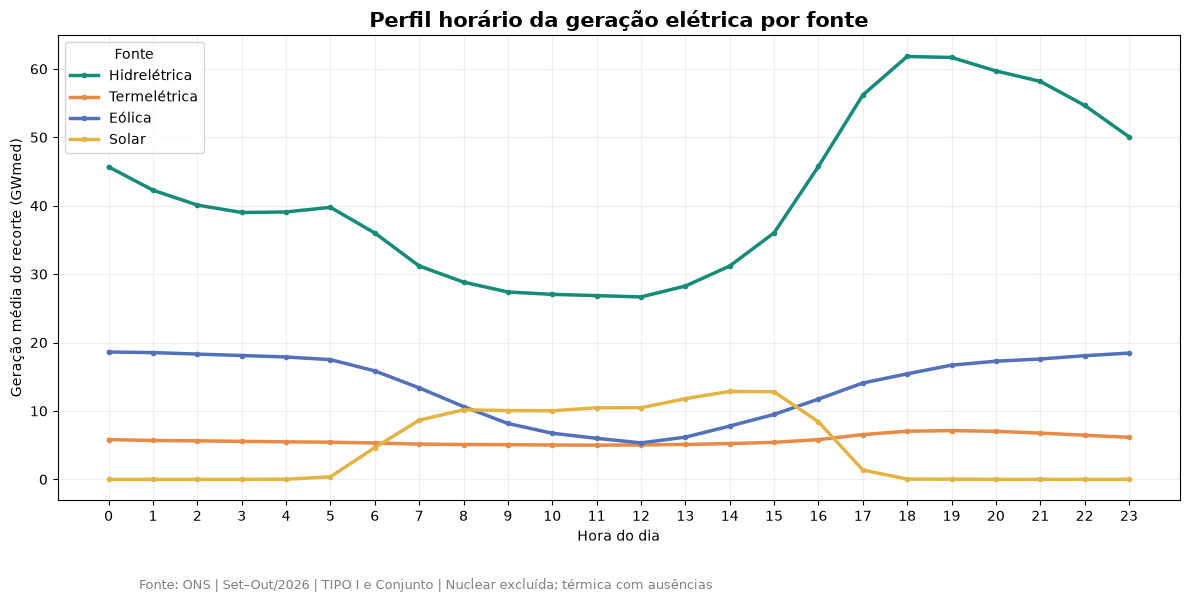

In [10]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

arquivo = (
    BASE_DIR / "data/gold/ons/geracao/"
    "geracao_horaria.parquet"
)

df = pd.read_parquet(arquivo)

# Período de análise: setembro e outubro completos
df = df[
    (df["din_instante"] >= "2026-09-01")
    & (df["din_instante"] < "2026-11-01")
].copy()

# Recorte operacional definido para este gráfico
modalidades = [
    "TIPO I",
    "Conjunto de Usinas"
]

df = df[
    df["cod_modalidadeoperacao"].isin(modalidades)
].copy()

fontes = {
    "HIDROELÉTRICA": "Hidrelétrica",
    "TÉRMICA": "Termelétrica",
    "EOLIELÉTRICA": "Eólica",
    "FOTOVOLTAICA": "Solar"
}

df = df[
    df["nom_tipousina"].isin(fontes)
].copy()

df["fonte"] = df["nom_tipousina"].map(fontes)

# Validar a cobertura temporal
horarios = df["din_instante"].nunique()

print("Horários distintos:", horarios)
print("Horários esperados:", 61 * 24)

if horarios != 61 * 24:
    raise ValueError(
        "O período não possui as 1.464 horas esperadas."
    )

# Cobertura por fonte
qualidade = (
    df.groupby("fonte", as_index=False)
    .agg(
        registros=("registros", "sum"),
        validos=("registros_validos", "sum"),
        ausentes=("valores_ausentes", "sum"),
        negativos=("valores_negativos", "sum")
    )
)

qualidade["cobertura_pct"] = (
    qualidade["validos"]
    / qualidade["registros"] * 100
)

print("\nCobertura por fonte:")
display(qualidade)

# Consolidar o valor disponível por instante e fonte
horaria_fonte = (
    df.groupby(
        ["din_instante", "fonte"],
        as_index=False
    )
    .agg(
        geracao_mwmed=(
            "geracao_soma",
            lambda x: x.sum(min_count=1)
        )
    )
)

horaria_fonte["hora"] = (
    horaria_fonte["din_instante"].dt.hour
)

# Média dos valores horários no período
perfil = (
    horaria_fonte.groupby(
        ["fonte", "hora"],
        as_index=False
    )
    .agg(
        geracao_media_mwmed=(
            "geracao_mwmed", "mean"
        )
    )
)

# Gráfico
fig, ax = plt.subplots(figsize=(12, 6))

cores = {
    "Hidrelétrica": "#168B79",
    "Termelétrica": "#E68A45",
    "Eólica": "#5271B9",
    "Solar": "#E3B443"
}

for fonte in fontes.values():
    dados = perfil[
        perfil["fonte"] == fonte
    ].sort_values("hora")

    ax.plot(
        dados["hora"],
        dados["geracao_media_mwmed"] / 1000,
        label=fonte,
        color=cores[fonte],
        linewidth=2.5,
        marker="o",
        markersize=3
    )

ax.set_title(
    "Perfil horário da geração elétrica por fonte",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Hora do dia")
ax.set_ylabel("Geração média do recorte (GWmed)")

ax.set_xticks(range(24))
ax.grid(alpha=0.2)
ax.legend(title="Fonte")
ax.set_axisbelow(True)

fig.text(
    0.12, 0.01,
    "Fonte: ONS | Set–Out/2026 | "
    "TIPO I e Conjunto | Nuclear excluída; térmica com ausências",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

PASTA_IMAGENS = BASE_DIR / "images"
PASTA_IMAGENS.mkdir(exist_ok=True)

plt.savefig(
    PASTA_IMAGENS / "13_perfil_horario_geracao.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 10. Preparação da Análise de Geração e Demanda
Identificação das lacunas de cobertura e validação da granularidade das fontes.

In [11]:

from pathlib import Path
import pandas as pd

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

SILVER_GERACAO = (
    BASE_DIR / "data/silver/ons/geracao"
)

arquivos = [
    SILVER_GERACAO / "geracao_2026_09.parquet",
    SILVER_GERACAO / "geracao_2026_10.parquet",
]

df_geracao = pd.concat(
    [pd.read_parquet(arquivo) for arquivo in arquivos],
    ignore_index=True
)

# Identificar usinas ou agrupamentos sem geração informada
termicas_nulas = df_geracao[
    (df_geracao["nom_tipousina"] == "TÉRMICA")
    & (
        df_geracao["cod_modalidadeoperacao"].isin([
            "TIPO I", "Conjunto de Usinas"
        ])
    )
    & df_geracao["val_geracao"].isna()
]

resumo = (
    termicas_nulas.groupby(
        [
            "nom_usina",
            "cod_modalidadeoperacao",
            "id_subsistema"
        ],
        dropna=False,
        as_index=False
    )
    .agg(
        registros_ausentes=("val_geracao", "size"),
        primeira_data=("din_instante", "min"),
        ultima_data=("din_instante", "max")
    )
    .sort_values("registros_ausentes", ascending=False)
)

display(
    resumo.groupby(["cod_modalidadeoperacao", "id_subsistema"], as_index=False)
    .agg(entidades=("nom_usina", "size"), registros_ausentes=("registros_ausentes", "sum"),
         primeira_data=("primeira_data", "min"), ultima_data=("ultima_data", "max"))
)


,cod_modalidadeoperacao,id_subsistema,entidades,registros_ausentes,primeira_data,ultima_data
0,Conjunto de Usinas,SE,1,1464,2026-09-01,2026-10-31 23:00:00


In [12]:

ARQUIVO_CARGA = (
    BASE_DIR / "data/silver/carga_energia.parquet"
)

df_carga = pd.read_parquet(ARQUIVO_CARGA)

print("Colunas da carga:")
print(df_carga.columns.tolist())

print("\nTipos de dados:")
print(df_carga.dtypes)

print("\nAmostra:")
display(df_carga.head(5))


Colunas da carga:
['id_subsistema', 'nom_subsistema', 'data', 'carga_mwmed', 'ano', 'mes', 'energia_mwh']

Tipos de dados:
id_subsistema                str
nom_subsistema               str
data              datetime64[us]
carga_mwmed              float64
ano                        int32
mes                        int32
energia_mwh              float64
dtype: object

Amostra:


,id_subsistema,nom_subsistema,data,carga_mwmed,ano,mes,energia_mwh
0,N,Norte,2024-01-01,6532.986042,2024,1,156791.665
1,NE,Nordeste,2024-01-01,11658.740083,2024,1,279809.762
2,S,Sul,2024-01-01,10472.403292,2024,1,251337.679
3,SE,Sudeste/Centro-Oeste,2024-01-01,35089.386708,2024,1,842145.281
4,N,Norte,2024-01-02,7154.334333,2024,1,171704.024


## 11. Visualização 14 - Geração e Carga Elétrica
Comparação da evolução diária da carga e da geração selecionada entre setembro e outubro de 2026.

Dias analisados: 61

Cobertura da geração selecionada:


,fonte,registros,ausentes,cobertura_pct
0,Eólica,218256,0,100.000000
1,Hidrelétrica,224232,0,100.000000
2,Solar,120192,0,100.000000
3,Termelétrica,129552,1464,98.869952


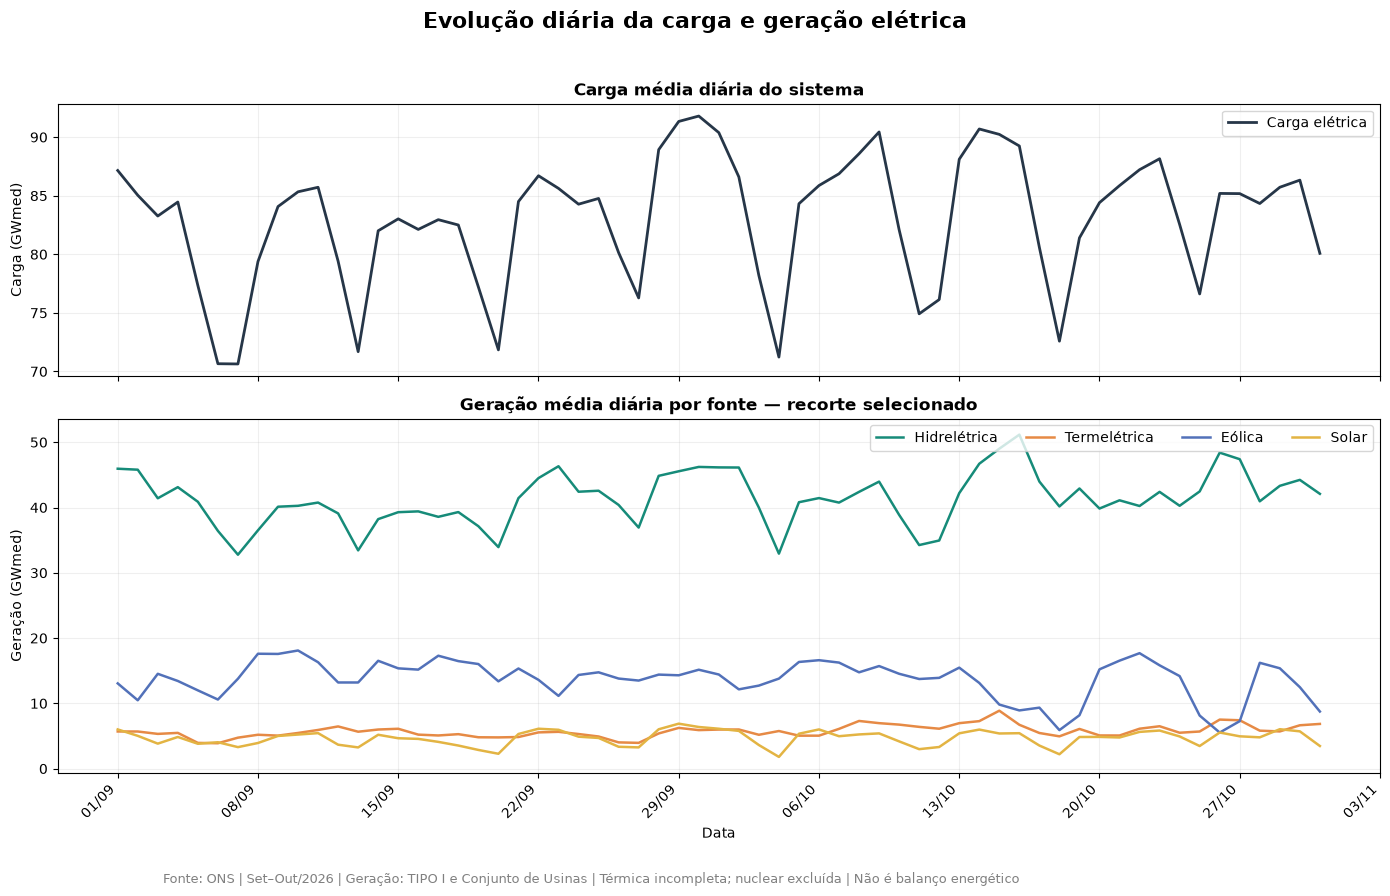

In [13]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# 1. CONFIGURAÇÕES
BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

DATA_INICIO = pd.Timestamp("2026-09-01")
DATA_FIM = pd.Timestamp("2026-11-01")

FONTES = {
    "HIDROELÉTRICA": "Hidrelétrica",
    "TÉRMICA": "Termelétrica",
    "EOLIELÉTRICA": "Eólica",
    "FOTOVOLTAICA": "Solar"
}

MODALIDADES = [
    "TIPO I",
    "Conjunto de Usinas"
]

CORES = {
    "Hidrelétrica": "#168B79",
    "Termelétrica": "#E68A45",
    "Eólica": "#5271B9",
    "Solar": "#E3B443"
}

# 2. CARGA DIÁRIA DO ONS
carga = pd.read_parquet(
    BASE_DIR / "data/silver/carga_energia.parquet"
)

carga["data"] = pd.to_datetime(carga["data"])

carga = carga[
    (carga["data"] >= DATA_INICIO)
    & (carga["data"] < DATA_FIM)
].copy()

# Cada subsistema possui carga média diária.
# Somar os quatro subsistemas para obter a carga total.
carga_diaria = (
    carga.groupby("data", as_index=False)
    .agg(
        carga_mwmed=("carga_mwmed", "sum"),
        subsistemas=("id_subsistema", "nunique")
    )
)

if not carga_diaria["subsistemas"].eq(4).all():
    raise ValueError(
        "Existem dias sem os quatro subsistemas."
    )

carga_diaria["carga_gwmed"] = (
    carga_diaria["carga_mwmed"] / 1000
)

# 3. GERAÇÃO HORÁRIA DO ONS
geracao = pd.read_parquet(
    BASE_DIR / "data/gold/ons/geracao/"
    "geracao_horaria.parquet"
)

geracao["din_instante"] = pd.to_datetime(
    geracao["din_instante"]
)

geracao = geracao[
    (geracao["din_instante"] >= DATA_INICIO)
    & (geracao["din_instante"] < DATA_FIM)
    & (
        geracao["cod_modalidadeoperacao"]
        .isin(MODALIDADES)
    )
    & (
        geracao["nom_tipousina"]
        .isin(FONTES)
    )
].copy()

geracao["fonte"] = (
    geracao["nom_tipousina"].map(FONTES)
)

# 4. CONSOLIDAÇÃO HORÁRIA
geracao_hora = (
    geracao.groupby(
        ["din_instante", "fonte"],
        as_index=False
    )
    .agg(
        geracao_mwmed=(
            "geracao_soma",
            lambda x: x.sum(min_count=1)
        ),
        registros=("registros", "sum"),
        ausentes=("valores_ausentes", "sum")
    )
)

geracao_hora["data"] = (
    geracao_hora["din_instante"].dt.normalize()
)

# 5. CONSOLIDAÇÃO DIÁRIA
geracao_diaria = (
    geracao_hora.groupby(
        ["data", "fonte"],
        as_index=False
    )
    .agg(
        geracao_mwmed=("geracao_mwmed", "mean"),
        horas=("din_instante", "nunique"),
        registros=("registros", "sum"),
        ausentes=("ausentes", "sum")
    )
)

# Não aceitar dias com horas faltantes.
if not geracao_diaria["horas"].eq(24).all():
    raise ValueError(
        "Existem dias com menos de 24 horários."
    )

geracao_diaria["geracao_gwmed"] = (
    geracao_diaria["geracao_mwmed"] / 1000
)

geracao_diaria["cobertura_pct"] = (
    100 * (
        1 -
        geracao_diaria["ausentes"]
        / geracao_diaria["registros"]
    )
)

# 6. ALINHAMENTO DAS DATAS
perfil = geracao_diaria.pivot(
    index="data",
    columns="fonte",
    values="geracao_gwmed"
)

perfil = perfil.reindex(
    columns=list(FONTES.values())
)

carga_serie = (
    carga_diaria.set_index("data")["carga_gwmed"]
)

datas_esperadas = pd.date_range(
    DATA_INICIO,
    DATA_FIM - pd.Timedelta(days=1),
    freq="D"
)

if (
    not perfil.index.equals(datas_esperadas)
    or perfil.isna().any().any()
    or not carga_serie.index.equals(datas_esperadas)
    or carga_serie.isna().any()
):
    raise ValueError(
        "Existem datas ou valores agregados ausentes."
    )

print("Dias analisados:", len(datas_esperadas))

print("\nCobertura da geração selecionada:")
display(
    geracao_diaria.groupby("fonte", as_index=False)
    .agg(
        registros=("registros", "sum"),
        ausentes=("ausentes", "sum")
    )
    .assign(
        cobertura_pct=lambda x:
        100 * (1 - x["ausentes"] / x["registros"])
    )
)

# 7. VISUALIZAÇÃO
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(14, 9),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 1.3]}
)

# Painel superior: carga total
ax1.plot(
    carga_serie.index,
    carga_serie.values,
    color="#263648",
    linewidth=2,
    label="Carga elétrica"
)

ax1.set_title(
    "Carga média diária do sistema",
    fontsize=12,
    fontweight="bold"
)

ax1.set_ylabel("Carga (GWmed)")
ax1.grid(alpha=0.2)
ax1.legend(loc="upper right")

# Painel inferior: geração selecionada
for fonte in FONTES.values():
    ax2.plot(
        perfil.index,
        perfil[fonte],
        label=fonte,
        color=CORES[fonte],
        linewidth=1.8
    )

ax2.set_title(
    "Geração média diária por fonte — recorte selecionado",
    fontsize=12,
    fontweight="bold"
)

ax2.set_ylabel("Geração (GWmed)")
ax2.set_xlabel("Data")
ax2.grid(alpha=0.2)
ax2.legend(ncol=4, loc="upper right")

ax2.xaxis.set_major_locator(
    mdates.WeekdayLocator(interval=1)
)

ax2.xaxis.set_major_formatter(
    mdates.DateFormatter("%d/%m")
)

plt.setp(
    ax2.get_xticklabels(),
    rotation=45,
    ha="right"
)

fig.suptitle(
    "Evolução diária da carga e geração elétrica",
    fontsize=16,
    fontweight="bold"
)

fig.text(
    0.12, 0.01,
    "Fonte: ONS | Set–Out/2026 | "
    "Geração: TIPO I e Conjunto de Usinas | "
    "Térmica incompleta; nuclear excluída | Não é balanço energético",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.04, 1, 0.96])

PASTA_IMAGENS = BASE_DIR / "images"
PASTA_IMAGENS.mkdir(exist_ok=True)

plt.savefig(
    PASTA_IMAGENS / "14_geracao_vs_carga_diaria.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 12. Visualização 15 — Carga por Dia da Semana

Comparação entre segunda–sexta e sábado–domingo, em setembro e outubro de 2026. Não há calendário de feriados; segunda–sexta não significa necessariamente dia útil.


,dia_num,dia_semana,carga_media_gwmed,dias_analisados
0,0,Segunda,81.641881,8
1,1,Terça,85.686342,9
2,2,Quarta,86.270213,9
3,3,Quinta,86.442591,9
4,4,Sexta,86.469772,9
5,5,Sábado,79.732323,9
6,6,Domingo,73.226964,8



Comparação:


,periodo,carga_media_gwmed,dias
0,Fim de semana,76.670978,17
1,Segunda a sexta,85.385348,44


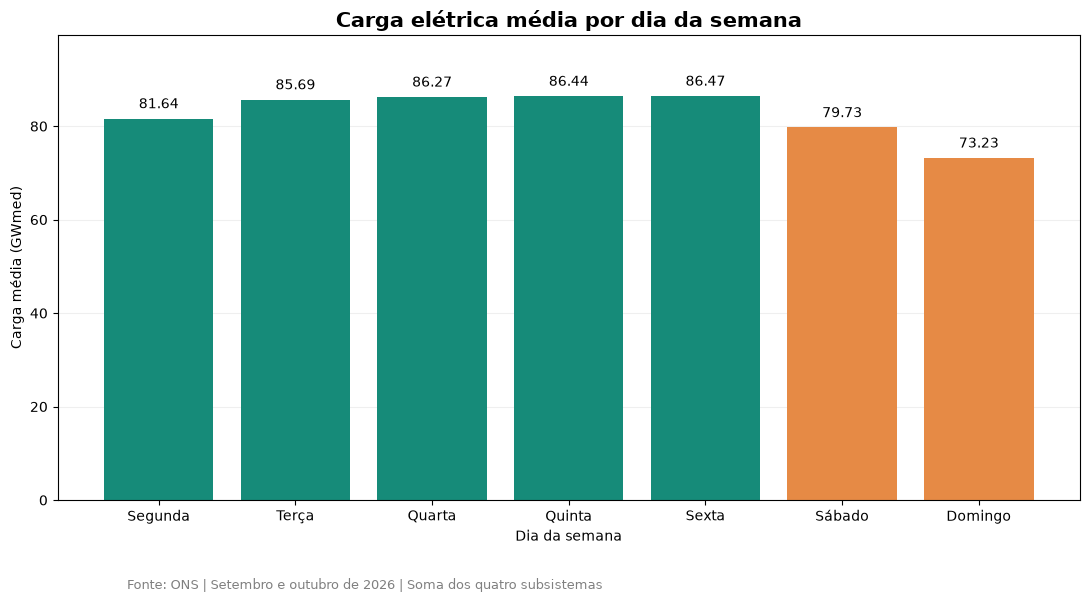

In [14]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

# Carregar Silver de carga
df_carga = pd.read_parquet(
    BASE_DIR / "data/silver/carga_energia.parquet"
)

df_carga["data"] = pd.to_datetime(df_carga["data"])

# Selecionar setembro e outubro de 2026
df_carga = df_carga[
    (df_carga["data"] >= "2026-09-01")
    & (df_carga["data"] < "2026-11-01")
].copy()

# Consolidar carga nacional diária
carga_diaria = (
    df_carga.groupby("data", as_index=False)
    .agg(
        carga_mwmed=("carga_mwmed", "sum"),
        subsistemas=("id_subsistema", "nunique")
    )
)

if len(carga_diaria) != 61:
    raise ValueError("Quantidade inesperada de dias.")

if not carga_diaria["subsistemas"].eq(4).all():
    raise ValueError("Há dias sem os quatro subsistemas.")

carga_diaria["carga_gwmed"] = (
    carga_diaria["carga_mwmed"] / 1000
)

# Identificar dias da semana
dias = {
    0: "Segunda",
    1: "Terça",
    2: "Quarta",
    3: "Quinta",
    4: "Sexta",
    5: "Sábado",
    6: "Domingo"
}

carga_diaria["dia_num"] = (
    carga_diaria["data"].dt.day_of_week
)

carga_diaria["dia_semana"] = (
    carga_diaria["dia_num"].map(dias)
)

# Resumo por dia da semana
resumo = (
    carga_diaria.groupby(
        ["dia_num", "dia_semana"],
        as_index=False
    )
    .agg(
        carga_media_gwmed=("carga_gwmed", "mean"),
        dias_analisados=("data", "count")
    )
    .sort_values("dia_num")
)

display(resumo)

# Comparar segunda a sexta e finais de semana, sem calendário de feriados
carga_diaria["periodo"] = (
    carga_diaria["dia_num"].apply(
        lambda x: "Fim de semana" if x >= 5
        else "Segunda a sexta"
    )
)

comparacao = (
    carga_diaria.groupby("periodo", as_index=False)
    .agg(
        carga_media_gwmed=("carga_gwmed", "mean"),
        dias=("data", "count")
    )
)

print("\nComparação:")
display(comparacao)

# Gráfico
fig, ax = plt.subplots(figsize=(11, 6))

cores = [
    "#168B79" if numero < 5 else "#E68A45"
    for numero in resumo["dia_num"]
]

barras = ax.bar(
    resumo["dia_semana"],
    resumo["carga_media_gwmed"],
    color=cores
)

ax.bar_label(
    barras,
    labels=[
        f"{valor:.2f}"
        for valor in resumo["carga_media_gwmed"]
    ],
    padding=5
)

ax.set_ylim(
    0,
    resumo["carga_media_gwmed"].max() * 1.15
)

ax.set_title(
    "Carga elétrica média por dia da semana",
    fontsize=15,
    fontweight="bold"
)

ax.set_ylabel("Carga média (GWmed)")
ax.set_xlabel("Dia da semana")

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.12, 0.01,
    "Fonte: ONS | Setembro e outubro de 2026 | "
    "Soma dos quatro subsistemas",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

PASTA_IMAGENS = BASE_DIR / "images"
PASTA_IMAGENS.mkdir(exist_ok=True)

plt.savefig(
    PASTA_IMAGENS / "15_carga_dia_semana.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 13. Visualização 16 - Correlação entre Carga e Geração
Análise da associação linear entre carga elétrica e geração diária por fonte.

Correlação com a carga elétrica:


,fonte,correlacao_pearson
0,Eólica,0.213436
1,Termelétrica,0.499111
2,Hidrelétrica,0.796125
3,Solar,0.888963


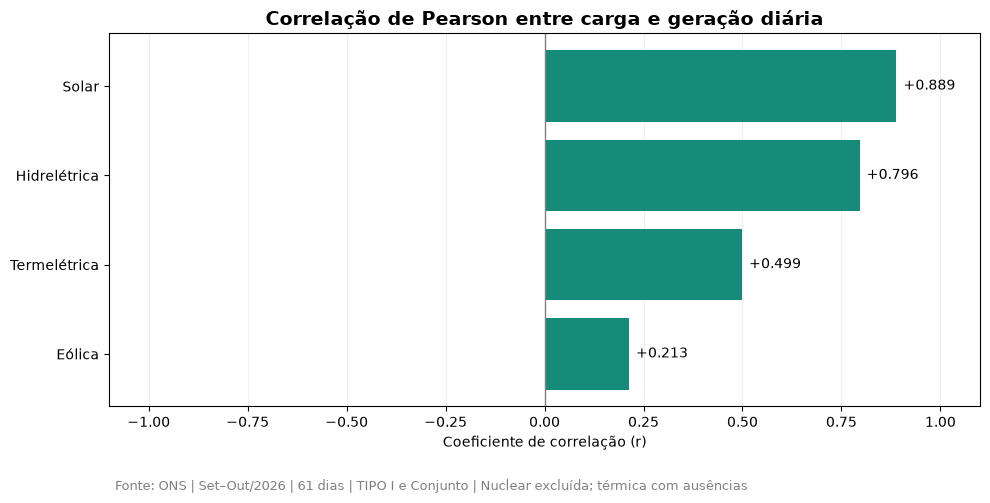

In [15]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path.cwd()
if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

INICIO = "2026-09-01"
FIM = "2026-11-01"

FONTES = {
    "HIDROELÉTRICA": "Hidrelétrica",
    "TÉRMICA": "Termelétrica",
    "EOLIELÉTRICA": "Eólica",
    "FOTOVOLTAICA": "Solar"
}

# 1. Carga diária
carga = pd.read_parquet(
    BASE_DIR / "data/silver/carga_energia.parquet"
)

carga["data"] = pd.to_datetime(carga["data"])
carga = carga[
    (carga["data"] >= INICIO) &
    (carga["data"] < FIM)
]

carga_diaria = (
    carga.groupby("data")
    .agg(
        carga_mwmed=("carga_mwmed", "sum"),
        subsistemas=("id_subsistema", "nunique")
    )
)

if not carga_diaria["subsistemas"].eq(4).all():
    raise ValueError("Carga com subsistemas ausentes.")

# 2. Geração horária
geracao = pd.read_parquet(
    BASE_DIR / "data/gold/ons/geracao/geracao_horaria.parquet"
)

geracao["din_instante"] = pd.to_datetime(
    geracao["din_instante"]
)

geracao = geracao[
    (geracao["din_instante"] >= INICIO) &
    (geracao["din_instante"] < FIM) &
    geracao["cod_modalidadeoperacao"].isin(
        ["TIPO I", "Conjunto de Usinas"]
    ) &
    geracao["nom_tipousina"].isin(FONTES)
].copy()

geracao["fonte"] = geracao["nom_tipousina"].map(FONTES)
geracao["data"] = geracao["din_instante"].dt.normalize()

# 3. Agregar sem duplicar horários
por_hora = (
    geracao.groupby(["din_instante", "data", "fonte"])
    .agg(
        geracao_mwmed=(
            "geracao_soma",
            lambda x: x.sum(min_count=1)
        )
    )
    .reset_index()
)

por_dia = (
    por_hora.groupby(["data", "fonte"])
    .agg(
        geracao_mwmed=("geracao_mwmed", "mean"),
        horas=("din_instante", "nunique")
    )
    .reset_index()
)

if not por_dia["horas"].eq(24).all():
    raise ValueError("Dias com menos de 24 horas.")

# 4. Integrar carga e geração
matriz = por_dia.pivot(
    index="data",
    columns="fonte",
    values="geracao_mwmed"
)

matriz["Carga elétrica"] = carga_diaria["carga_mwmed"]

datas_esperadas = pd.date_range(
    "2026-09-01", "2026-10-31", freq="D"
)

matriz = matriz.reindex(datas_esperadas)

if matriz.isna().any().any():
    raise ValueError("Datas ou valores ausentes.")

# 5. Correlação de Pearson
correlacoes = (
    matriz.corr(method="pearson")["Carga elétrica"]
    .drop("Carga elétrica")
    .sort_values()
)

resultado = correlacoes.reset_index()
resultado.columns = ["fonte", "correlacao_pearson"]

print("Correlação com a carga elétrica:")
display(resultado)

# 6. Visualização
fig, ax = plt.subplots(figsize=(10, 5))

cores = [
    "#168B79" if valor >= 0 else "#E68A45"
    for valor in correlacoes.values
]

barras = ax.barh(
    correlacoes.index,
    correlacoes.values,
    color=cores
)

ax.bar_label(
    barras,
    labels=[f"{v:+.3f}" for v in correlacoes],
    padding=5
)

ax.set_xlim(-1.1, 1.1)
ax.axvline(0, color="gray", linewidth=1)

ax.set_title(
    "Correlação de Pearson entre carga e geração diária",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Coeficiente de correlação (r)")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.12, 0.01,
    "Fonte: ONS | Set–Out/2026 | 61 dias | "
    "TIPO I e Conjunto | Nuclear excluída; térmica com ausências",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

PASTA_IMAGENS = BASE_DIR / "images"
PASTA_IMAGENS.mkdir(exist_ok=True)

plt.savefig(
    PASTA_IMAGENS / "16_correlacao_carga_geracao.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 14. Visualização 17 — Correlação Ajustada pelo Dia da Semana

Pearson original mede a associação linear entre as séries diárias. O ajuste subtrai a média de cada dia da semana em cada série e correlaciona os resíduos: remove o padrão médio semanal, sem controlar clima, tendência, despacho, feriados ou outras variáveis.


Comparação das correlações:


,Original,Ajustada,Diferenca
fonte,,,
Solar,0.889,0.778,-0.111
Hidrelétrica,0.796,0.711,-0.085
Termelétrica,0.499,0.440,-0.059
Eólica,0.213,-0.183,-0.397


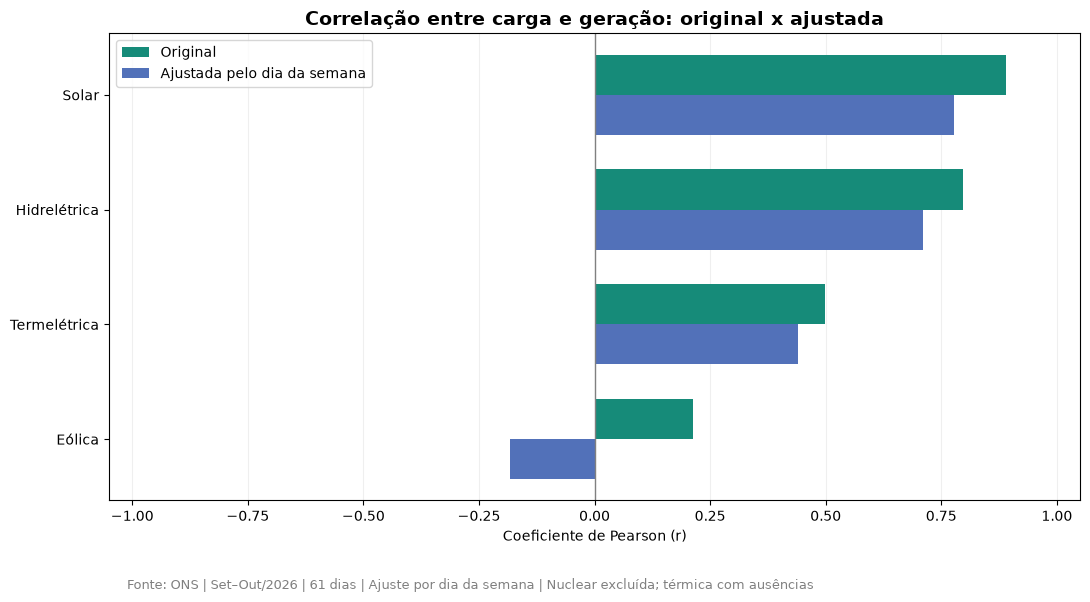

In [16]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

BASE_DIR = Path.cwd()

if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

# Utilizar a matriz diária do Gráfico 16
# Colunas: Carga elétrica, Solar,
# Hidrelétrica, Termelétrica e Eólica

colunas = [
    "Carga elétrica",
    "Solar",
    "Hidrelétrica",
    "Termelétrica",
    "Eólica"
]

dados = matriz[colunas].copy()

dados.index = pd.to_datetime(dados.index)
dados = dados.sort_index()

if len(dados) != 61 or dados.isna().any().any():
    raise ValueError(
        "Esperadas 61 observações completas."
    )

# Correlação original
original = dados.corr(method="pearson")[
    "Carga elétrica"
].drop("Carga elétrica")

# Ajustar cada variável pela média do dia da semana
dados["dia_semana"] = dados.index.day_of_week

ajustado = dados[colunas].copy()

for coluna in colunas:
    media_dia_semana = (
        dados.groupby("dia_semana")[coluna]
        .transform("mean")
    )

    ajustado[coluna] = (
        dados[coluna] - media_dia_semana
    )

# Correlação das séries ajustadas
corr_ajustada = ajustado.corr(
    method="pearson"
)["Carga elétrica"].drop("Carga elétrica")

# Comparação
resultado = pd.DataFrame({
    "Original": original,
    "Ajustada": corr_ajustada
})

resultado["Diferenca"] = (
    resultado["Ajustada"] - resultado["Original"]
)

resultado = resultado.sort_values(
    "Original",
    ascending=False
)

print("Comparação das correlações:")
display(resultado.round(3))

# Visualização
fig, ax = plt.subplots(figsize=(11, 6))

posicoes = list(range(len(resultado)))
largura = 0.35

ax.barh(
    [p - largura / 2 for p in posicoes],
    resultado["Original"],
    height=largura,
    label="Original",
    color="#168B79"
)

ax.barh(
    [p + largura / 2 for p in posicoes],
    resultado["Ajustada"],
    height=largura,
    label="Ajustada pelo dia da semana",
    color="#5271B9"
)

ax.set_yticks(posicoes)
ax.set_yticklabels(resultado.index)
ax.invert_yaxis()

ax.axvline(0, color="gray", linewidth=1)
ax.set_xlim(-1.05, 1.05)

ax.set_title(
    "Correlação entre carga e geração: "
    "original x ajustada",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Coeficiente de Pearson (r)")
ax.set_ylabel("")
ax.legend()
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.12, 0.01,
    "Fonte: ONS | Set–Out/2026 | 61 dias | "
    "Ajuste por dia da semana | Nuclear excluída; térmica com ausências",
    fontsize=9,
    color="gray"
)

plt.tight_layout(rect=[0, 0.06, 1, 1])

PASTA_IMAGENS = BASE_DIR / "images"
PASTA_IMAGENS.mkdir(exist_ok=True)

plt.savefig(
    PASTA_IMAGENS / "17_correlacao_ajustada.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## 15. Robustez das Correlações

Comparação exploratória entre setembro (30 dias), outubro (31 dias) e o conjunto (61 dias). Os resultados não demonstram causalidade nem significância estatística.


In [17]:

import pandas as pd

# Matriz diária criada no Gráfico 16
dados = matriz[
    [
        "Carga elétrica",
        "Solar",
        "Hidrelétrica",
        "Termelétrica",
        "Eólica"
    ]
].copy()

dados.index = pd.to_datetime(dados.index)
dados = dados.sort_index()

fontes = [
    "Solar",
    "Hidrelétrica",
    "Termelétrica",
    "Eólica"
]

resultados = []

for mes, nome in [(9, "Setembro"), (10, "Outubro")]:
    amostra = dados[dados.index.month == mes].copy()

    # Pearson original dentro do mês
    original = amostra.corr(method="pearson")[
        "Carga elétrica"
    ]

    # Remover a média do dia da semana
    ajustada = amostra.copy()
    dia_semana = amostra.index.day_of_week

    for coluna in ajustada.columns:
        medias = (
            ajustada.groupby(dia_semana)[coluna]
            .transform("mean")
        )

        ajustada[coluna] = (
            ajustada[coluna] - medias
        )

    correlacao_ajustada = ajustada.corr(
        method="pearson"
    )["Carga elétrica"]

    for fonte in fontes:
        resultados.append({
            "mes": nome,
            "fonte": fonte,
            "dias": len(amostra),
            "original": original[fonte],
            "ajustada": correlacao_ajustada[fonte]
        })

df_robustez = pd.DataFrame(resultados)

print("Correlação por mês:")
display(df_robustez.round(3))


Correlação por mês:


,mes,fonte,dias,original,ajustada
0,Setembro,Solar,30,0.857,0.808
1,Setembro,Hidrelétrica,30,0.887,0.829
2,Setembro,Termelétrica,30,0.560,0.268
3,Setembro,Eólica,30,0.250,-0.057
4,Outubro,Solar,31,0.927,0.711
5,Outubro,Hidrelétrica,31,0.699,0.566
6,Outubro,Termelétrica,31,0.446,0.407
7,Outubro,Eólica,31,0.309,-0.177


### Interpretação e limites

A correlação hidrelétrica ajustada cai de aproximadamente **0,829 em setembro** para **0,566 em outubro**; antes do ajuste, é aproximadamente 0,887 e 0,699. A eólica ajustada fica próxima de zero em setembro (**−0,057**) e negativa em outubro (**−0,177**); os coeficientes originais são aproximadamente 0,250 e 0,309. No conjunto dos 61 dias, os ajustados são cerca de 0,711 para hidrelétrica e −0,183 para eólica.

A mudança por mês e após o ajuste mostra sensibilidade ao período e ao padrão semanal. Amostras de 30, 31 e 61 dias podem ter dependência temporal; clima, despacho, tendência, composição das usinas e outras variáveis não foram controlados. As correlações descrevem associação no recorte selecionado e não identificam efeito causal nem permitem inferir significância sem metodologia adequada.
